### Table of Contributions
| Yu Xiu  | Jerry | Tahseen |
|-------|-----|--------|
| Data generation | Optimizer and scheduler | |
| Training loop | | |

### Step 1: Install necessary packages

In [1]:
!pip install matplotlib
!pip install torch numpy transformers datasets tiktoken wandb tqdm

  Using cached torch-2.14.1-cp314-cp314-manylinux_2_28_x86_64.whl.metadata (37 kB)
  Using cached transformers-5.20.2-py3-none-any.whl.metadata (31 kB)
  Using cached datasets-5.1.0-py3-none-any.whl.metadata (24 kB)
  Using cached tiktoken-0.14.0-cp314-cp314-manylinux_2_28_x86_64.whl.metadata (6.7 kB)
  Using cached wandb-0.31.0-py3-none-manylinux_2_28_x86_64.whl.metadata (12 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached filelock-4.2.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached setuptools-84.2.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached cuda_toolkit-13.0.3.0-py2.py3-none-any.whl.metadata (17 kB)
  Using cached cuda_bindings-13.4.4-cp314-cp314-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl

### Step 2: Package imports and configuration

In [2]:
import sys
import os
sys.path.append(os.path.abspath("..")) 
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import pickle
from model import GPT, GPTConfig
import random
from tqdm import tqdm
import time
import json
import matplotlib.pyplot as plt
# Configuration
beta = 0.5
device = 'cuda' if torch.cuda.is_available() else 'cpu'
base_lr = 1e-4
epochs = 15 # use 15 epochs instead
batch_size = 64
max_length =64
num_samples = 1
max_new_tokens = 200
temperature = 0.8
top_k = 200
weight_decay = 0.01 #PLACEHOLDER
# tokenizer
with open("../sft/meta.pkl", "rb") as f:
    meta = pickle.load(f)
stoi, itos = meta["stoi"], meta["itos"]
def encode(s): return [stoi[c] for c in s]
def decode(l): return ''.join([itos[i] for i in l])

### Step 3: Define helper functions
- `compute_logprob`: given a batch of token sequences, computes the average log-probability the model assigns to each sequence (shifted by one position for next-token prediction), ignoring padding tokens. This is the per-sample likelihood used by the DPO loss.
- `pad_or_truncate`: pads a token sequence with zeros or truncates it so every sequence in a batch has the same fixed `max_length`.
- `get_batches`: shuffles the `positive`/`negative` pairs and yields them in batches as encoded, padded tensors ready for the model.

In [3]:
def compute_logprob(input_ids):
    inputs = input_ids[:, :-1]
    targets = input_ids[:, 1:]
    logits, _ = gpt(inputs, full_seq=True)
    B, T, V = logits.size()
    logits_flat = logits.reshape(-1, V)
    targets_flat = targets.reshape(-1)
    loss = F.cross_entropy(logits_flat, targets_flat, ignore_index=0, reduction='none')
    loss = loss.reshape(B, T)
    attention_mask = (targets != 0).float()
    loss = (loss * attention_mask).sum(dim=1) / attention_mask.sum(dim=1)
    return -loss 

def pad_or_truncate(seq, max_length):
    return seq[-max_length:] if len(seq) > max_length else seq + [0] * (max_length - len(seq))

def get_batches(lines, batch_size):
    random.shuffle(lines)
    #for l in lines:
    #    print(l[1])
    for i in range(0, len(lines), batch_size):
        batch = lines[i:i+batch_size]
        if len(batch) < batch_size:
            continue
        neg_inputs = [pad_or_truncate(encode(p['negative'] + '\n\n\n\n'), max_length) for p in batch]
        pos_inputs = [pad_or_truncate(encode(p['positive'] + '\n\n\n\n'), max_length) for p in batch]
        neg_tensor = torch.tensor(neg_inputs, dtype=torch.long, device=device)
        pos_tensor = torch.tensor(pos_inputs, dtype=torch.long, device=device)
        yield neg_tensor, pos_tensor

### Step 4: Load the pretrained NanoGPT model
This loads the SFT checkpoint from `../sft/gpt.pt`, which acts as the starting point (skeleton) for DPO training. 

In [5]:
ckpt = torch.load("../sft/gpt.pt", map_location=device)
gptconf = GPTConfig(**ckpt['model_args'])
gpt = GPT(gptconf)
state_dict = ckpt['model']
unwanted_prefix = '_orig_mod.'
for k in list(state_dict.keys()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)
gpt.to(device).train()

GPT(
  (transformer): ModuleDict(
    (wte): Embedding(74, 348)
    (wpe): Embedding(256, 348)
    (drop): Dropout(p=0.2, inplace=False)
    (h): ModuleList(
      (0-5): 6 x Block(
        (ln_1): LayerNorm()
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=348, out_features=1044, bias=False)
          (c_proj): Linear(in_features=348, out_features=348, bias=False)
          (attn_dropout): Dropout(p=0.2, inplace=False)
          (resid_dropout): Dropout(p=0.2, inplace=False)
        )
        (ln_2): LayerNorm()
        (mlp): MLP(
          (c_fc): Linear(in_features=348, out_features=1392, bias=False)
          (gelu): GELU(approximate='none')
          (c_proj): Linear(in_features=1392, out_features=348, bias=False)
          (dropout): Dropout(p=0.2, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm()
  )
  (lm_head): Linear(in_features=348, out_features=74, bias=False)
)

#### Step 4.1: Generate negative training data sets with pretrained NanoGPT
1. Define about 100k prompts in data/prompts.json
2. To obtain the negative answers, simply append 'Sorry, I do not know' to the prompts
3. To obtain the positive answers, use Python regex to answer the prompts.

In [ ]:
prompt_path = './prompts.json'
negative_output_path = './generated_neg.json'
final_output_path = './pos_neg_pairs.json'

##### Experimenting Negative Prompts with NanoGPT
Here, we allowed NanoGPT to manually answer 2000 prompts as an experiment.

In [ ]:
%%script false --no-raise-error
NUM_PROMPTS = 2000  # scale up towards 100k 

def generate_prompts(n):
    prompts = []
    for _ in range(n):
        kind = random.choice(["add", "sub", "mul", "div", "find_add", "find_sub", "find_mul"])
        a = random.randint(1, 99)
        b = random.randint(1, 99)
        if kind == "add":
            prompts.append(f"{a}+{b}=?")
        elif kind == "sub":
            prompts.append(f"{a}-{b}=?")
        elif kind == "mul":
            prompts.append(f"{a}*{b}=?")
        elif kind == "div":
            divisor = random.randint(1, 12)
            quotient = random.randint(1, 20)
            prompts.append(f"{divisor * quotient}/{divisor}=?")
        elif kind == "find_add":
            prompts.append(f"x+{a}={a + b},x=?")
        elif kind == "find_sub":
            prompts.append(f"{a}-x={a - b},x=?")
        elif kind == "find_mul":
            prompts.append(f"x*{a}={a * b},x=?")
    return prompts

prompts = generate_prompts(NUM_PROMPTS)
with open(prompt_path, "w", encoding="utf-8") as f:
    json.dump(prompts, f, indent=4)

def generate_negative(prompt):
    """Sample a (likely weak/wrong) response from the pretrained NanoGPT."""
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    with torch.no_grad():
        out_idx, _ = gpt.generate(idx, max_new_tokens=max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(out_idx[0].tolist())

gpt.eval()
negatives = [generate_negative(p) for p in tqdm(prompts, desc="Generating negatives with NanoGPT")]
gpt.train() 

with open(negative_output_path, "w", encoding="utf-8") as f:
    json.dump(negatives, f, indent=4)

print(f"Wrote {len(prompts)} prompts to {prompt_path} and {len(negatives)} negatives to {negative_output_path}")


Generating the negatives for 100k samples with NanoGPT takes too long on CPU.
The remaining 98000 prompts will be answered manually as mentioned previously.

In [ ]:
%%script false --no-raise-error
NUM_PROMPTS = 98000
prompts = generate_prompts(NUM_PROMPTS)
with open(prompt_path, "w", encoding="utf-8") as f:
    json.dump(prompts, f, indent=4)

In [ ]:
%%script false --no-raise-error
import re
def solve_prompt(prompt: str) -> str:
    # 1. linear equation of type: x*b=c,x=?
    m = re.fullmatch(r"x\*(\d+)=(\d+),x=\?", prompt)
    if m:
        b, c = int(m.group(1)), int(m.group(2))
        ans = c // b
        return f"{prompt} The answer is {ans} because {c}/{b} equals {ans}."

    # 2. linear equation of type: x+b=c,x=?
    m = re.fullmatch(r"x\+(-?\d+)=(-?\d+),x=\?", prompt)
    if m:
        b, c = int(m.group(1)), int(m.group(2))
        ans = c - b
        return f"{prompt} The answer is {ans} because {c}-{b} equals {ans}."

    # 3. linear equation of type: a-x=c,x=?
    m = re.fullmatch(r"(-?\d+)-x=(-?\d+),x=\?", prompt)
    if m:
        a, c = int(m.group(1)), int(m.group(2))
        ans = a - c
        return f"{prompt} The answer is {ans} because {a}-{c} equals {ans}."

    # 4. simple arithmetic statement: a*b=?
    m = re.fullmatch(r"(-?\d+)\*(-?\d+)=\?", prompt)
    if m:
        a, b = int(m.group(1)), int(m.group(2))
        ans = a * b
        return f"{prompt} The answer is {ans} because {a}*{b} equals {ans}."

    # 5. simple arithmetic statement: a/b=?
    m = re.fullmatch(r"(-?\d+)/(-?\d+)=\?", prompt)
    if m:
        a, b = int(m.group(1)), int(m.group(2))
        ans = a // b
        return f"{prompt} The answer is {ans} because {a}/{b} equals {ans}."

    # 6. simple arithmetic statement: a+b=?
    m = re.fullmatch(r"(-?\d+)\+(-?\d+)=\?", prompt)
    if m:
        a, b = int(m.group(1)), int(m.group(2))
        ans = a + b
        return f"{prompt} The answer is {ans} because {a}+{b} equals {ans}."

    # 7. simple arithmetic statement: a-b=?
    m = re.fullmatch(r"(-?\d+)-(-?\d+)=\?", prompt)
    if m:
        a, b = int(m.group(1)), int(m.group(2))
        ans = a - b
        return f"{prompt} The answer is {ans} because {a}-{b} equals {ans}."

    raise ValueError(f"Unrecognized prompt pattern: {prompt}")

In [ ]:
%%script false --no-raise-error
with open(prompt_path, "r", encoding="utf-8") as f:
    prompts = json.load(f)

    # Load existing pairs (the first 2,000)
    try:
        with open(final_output_path, "r", encoding="utf-8") as f:
            pairs = json.load(f)
    except FileNotFoundError:
        pairs = []

    # Process remaining prompts (index 2000 onwards)
    start_idx = len(pairs)
    remaining_prompts = prompts[start_idx:]

    for p in tqdm(remaining_prompts, desc="Generating QA pairs", unit="prompt"):
        pairs.append({
            "negative": f"{p} Sorry, I don't know.",
            "positive": solve_prompt(p)
        })

    print("Saving to file...")
    with open(final_output_path, "w", encoding="utf-8") as f:
        # Omit indent=4 to save space
        json.dump(pairs, f)

    print("Done!")

### Step 5: Load Data (**students are required to complete this part!**)

In [ ]:
# 1. Load data from ./data/pos_neg_pairs.json
data_path = './pos_neg_pairs.json'

# open json file, parse as a json document. With the format from pos_neg_pairs.json, lines is a list of dicts, with each dict having a "negative" and "positive" answer.
with open(data_path, "r", encoding="utf-8") as f:
    lines = json.load(f)


### Step 6: Build the optimizer and scheduler (**students are required to complete this part!**)
The recommended AdamW optimizer and cosine annealing for the learning rate was used.

In [8]:
# betas defined at the start of ipynb
# docs.pytorch.org/docs/main/generated/torch.optim.adamw.AdamW_class.html
optimizer = torch.optim.AdamW(gpt.parameters(), lr=base_lr, weight_decay=0.01)
total_steps = len(lines) // batch_size

# if scheduler is called once per batch, T_max should be steps * epochs so that the scheduler operates as inteded over the whole training period.
# https://docs.pytorch.org/docs/main/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps * epochs, eta_min=base_lr*0.1)

Cosine annealing scheduler curve below: 
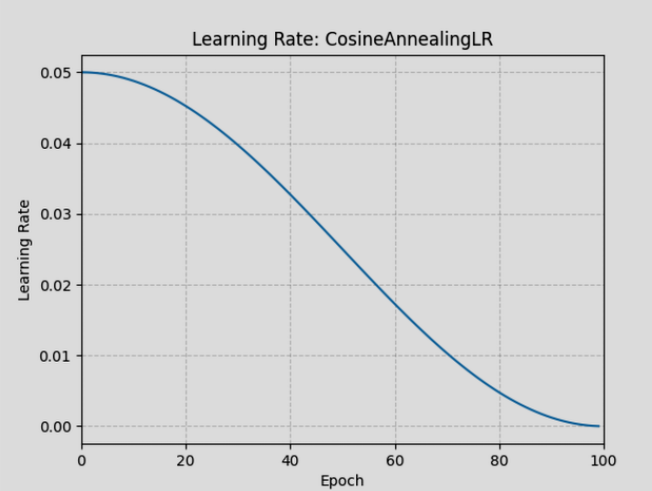
https://docs.pytorch.org/docs/main/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html

### Step 7: Begin training (**students are required to complete this part!**)
Training happens on the `gpt` model skeleton loaded in Step 4 from the SFT checkpoint.

To build a Direct Preference Optimization (DPO) model, DPO loss is used to perform gradient descent.  `-F.logsigmoid((pos_logprob - neg_logprob) / beta).mean()`  pushes the model to assign higher likelihood to preferred positive responses over the negative ones.

An additional `- pos_logprob.mean() * 0.1` term further encourages the raw likelihood of positive responses, helping stabilize training.

In [ ]:
for epoch in range(epochs):
    pbar = tqdm(get_batches(lines, batch_size))
    for step, (neg_tensor,pos_tensor) in enumerate(pbar):
        ###########################################################
        # 1. reset any previous gradients
        optimizer.zero_grad() 

        # 2. forward pass:
        # compute DPO loss
        # https://apxml.com/courses/llm-alignment-safety/chapter-3-advanced-alignment-algorithms/practice-implementing-dpo-loss
        neg_logprob = compute_logprob(neg_tensor)
        pos_logprob = compute_logprob(pos_tensor)

        loss = -F.logsigmoid((pos_logprob - neg_logprob) / beta).mean() - pos_logprob.mean() * 0.1
        # 3. backward pass
        loss.backward()

        torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0) #prevent exploding gradients

        # 4. update model params using previously defined optimizer & scheduler in step 6
        optimizer.step() 
        scheduler.step()

        # 5. log output
        pbar.set_description(f"Epoch {epoch + 1}/{epochs} | Loss: {loss.item():.4f}")
        ###########################################################
    ckpt_path = f"./dpo.pt"
    torch.save({
        "model_state_dict": gpt.state_dict(),
        "model_args": ckpt['model_args'],
    }, ckpt_path)
    print(f"Saved checkpoint to {ckpt_path}")

Epoch 1/15 | Loss: 0.0272: : 1562it [01:16, 20.48it/s]


Saved checkpoint to ./dpo.pt


Epoch 2/15 | Loss: 0.0257: : 1562it [01:15, 20.72it/s]


Saved checkpoint to ./dpo.pt


Epoch 3/15 | Loss: 0.0238: : 1562it [01:15, 20.65it/s]


...

Saved checkpoint to ./dpo.pt


Epoch 14/15 | Loss: 0.0187: : 1562it [01:16, 20.50it/s]


Saved checkpoint to ./dpo.pt


Epoch 15/15 | Loss: 0.0192: : 1562it [01:16, 20.52it/s]

Saved checkpoint to ./dpo.pt


#### Step 7.1: Train model with checkpoints
Training takes long on CPU. In the event of no GPU, training with checkpointing may be needed

In [ ]:
%%script false --no-raise-error
import itertools

ckpt_path = "./dpo.pt"
save_every = 50  # checkpoint often since each step is slow on CPU

# Recalculate total_steps for the current dataset
total_steps = len(lines) // batch_size

# Resume from the last checkpoint if one exists
start_epoch, start_step = 0, 0
if os.path.exists(ckpt_path):
    resume_ckpt = torch.load(ckpt_path, map_location=device)
    gpt.load_state_dict(resume_ckpt["model_state_dict"])
    optimizer.load_state_dict(resume_ckpt["optimizer_state_dict"])
    
    # Only load scheduler if total step budget has not changed drastically;
    # otherwise, re-initialize or let it step from the current position.
    try:
        scheduler.load_state_dict(resume_ckpt["scheduler_state_dict"])
    except Exception as e:
        print(f"Notice: Scheduler state skipped due to shape change: {e}")
        
    start_epoch = resume_ckpt["epoch"]
    start_step = max(0, resume_ckpt["step"] + 1)
    print(f"Resuming from epoch {start_epoch}, step {start_step}")

for epoch in range(start_epoch, epochs):
    print(f"\n--- Starting Epoch {epoch} ---")
    # Deterministic epoch shuffle so islice correctly resumes without missing/duplicating batches
    epoch_lines = list(lines)
    random.seed(42 + epoch)
    random.shuffle(epoch_lines)

    # only the resumed epoch skips ahead; later epochs start at step 0
    offset = start_step if epoch == start_epoch else 0
    batch_iter = itertools.islice(get_batches(epoch_lines, batch_size), offset, None)
    pbar = tqdm(batch_iter, initial=offset, total=total_steps, desc=f"Epoch {epoch}")
    for step, (neg_tensor, pos_tensor) in enumerate(pbar, start=offset):
        ###########################################################
        # 1. reset any previous gradients
        optimizer.zero_grad() 

        # 2. forward pass:
        # compute DPO loss
        # https://apxml.com/courses/llm-alignment-safety/chapter-3-advanced-alignment-algorithms/practice-implementing-dpo-loss
        neg_logprob = compute_logprob(neg_tensor)
        pos_logprob = compute_logprob(pos_tensor)

        loss = -F.logsigmoid((pos_logprob - neg_logprob) / beta).mean() - pos_logprob.mean() * 0.1
        # 3. backward pass
        loss.backward()

        torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0) #prevent exploding gradients

        # 4. update model params
        optimizer.step() 
        scheduler.step()

        # 5. log
        pbar.set_description(f"Epoch {epoch + 1}/{epochs} | Loss: {loss.item():.4f}")
        ###########################################################
        # save model state
        if (step + 1) % save_every == 0:
            torch.save({
                "model_state_dict": gpt.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "model_args": ckpt['model_args'],
                "epoch": epoch,
                "step": step,
            }, ckpt_path)

    # Reset step counter for future epochs
    start_step = 0

    torch.save({
        "model_state_dict": gpt.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "model_args": ckpt['model_args'],
        "epoch": epoch + 1,
        "step": -1,
    }, ckpt_path)
    print(f"Saved checkpoint to {ckpt_path} (epoch {epoch} complete)")

Resuming from epoch 2, step 4650

--- Starting Epoch 2 ---


Epoch 2: 4650it [00:06, ?it/s]


Saved checkpoint to ./dpo.pt (epoch 2 complete)

--- Starting Epoch 3 ---


Epoch 3: 100%|██████████| 1562/1562 [3:40:34<00:00,  8.47s/it]  


Saved checkpoint to ./dpo.pt (epoch 3 complete)

--- Starting Epoch 4 ---


Epoch 4: 100%|██████████| 1562/1562 [3:35:10<00:00,  8.27s/it]  


Saved checkpoint to ./dpo.pt (epoch 4 complete)


*It should be noted that checkpointing was not used for final run.

### Step 8: Begin testing (**students are required to complete this part!**)

In [10]:
# Load the fine-tuned model
ckpt_path = "./dpo.pt"
checkpoint = torch.load(ckpt_path, map_location=device)
gptconf = GPTConfig(**checkpoint['model_args'])
gpt = GPT(gptconf).to(device)
try:
    state_dict = checkpoint['model']
except:
    state_dict = checkpoint['model_state_dict']
unwanted_prefix = '_orig_mod.'
for k,v in list(state_dict.items()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)
# Test
gpt.eval()
test_set = ["17+19=?", "3*17=?", "72/4=?", "72-x=34,x=?", "x*11=44,x=?", "3*17=?", "72/4=?", "72-x=34,x=?", "2-70=?"]

with torch.no_grad():
    for prompt in test_set: 
        prompt_ids = encode(prompt)
        ###########################################################
        # 1. Convert each encoded prompt into a tensor (shape: [1, seq_len])
        # gpt.generate expects a batch dimension (B, T), so wrap prompt_ids in a list
        x = torch.tensor([prompt_ids], dtype=torch.long, device=device)

        with torch.no_grad():
            # 2. pass the tensor, tokens, temperature, and top k into gpt
            # gpt.generate returns (idx, hidden_state); unpack idx before indexing the batch dim
            y, _ = gpt.generate(x, max_new_tokens=max_new_tokens, temperature=temperature, top_k=top_k)

        # Decode only the generated completion tokens
        generated_ans = decode(y[0][len(prompt_ids):].tolist())
        print(f"{prompt} {generated_ans}")
        ###########################################################

17+19=?  The answer is 36 because 17+19 equals 36.
3*17=?  The answer is 51 because 3*17 equals 51.
72/4=?  The answer is 18 because 72/4 equals 18.
72-x=34,x=?  The answer is 38 because 72-34 equals 38.
x*11=44,x=?  The answer is 4 because 44/11 equals 4.
3*17=?  The answer is 51 because 3*17 equals 51.
72/4=?  The answer is 18 because 72/4 equals 18.
72-x=34,x=?  The answer is 38 because 72-34 equals 38.
2-70=?  The answer is -68 because 2-70 equals -68.


### Conclusion

Although it achieved high accuracy on the final test set, the model is unlikely to generalize well on unseen integer mathematical equations.

This is because the model was not trained to perform mathematical calculations, but instead on how to preferentially produce 'accurate' integer answers based on strings of digits. DPO only reshapes the model's *preference* between two candidate completions it already knows how to produce (from SFT) — it does not teach new reasoning or computation ability. 

Performance is therefore bounded by what the base `gpt.pt` model could already generate, and by the coverage of the `pos_neg_pairs.json` training distribution (e.g. digit lengths, operation types). 

Therefore, extending generalization would likely require broader SFT pretraining data (larger digit ranges, more operation types).
